# Single-Frame Detection Debugger

Inspects the background-subtraction segmentation pipeline (`compute_bob_centroid`) for any single video and frame index spotted in `results/plots/{video}_trajectory.png`.

Set `VIDEO_NAME`, `FRAME_INDEX`, and the detection parameters (`THRESHOLD_LOW`, `THRESHOLD_HIGH`, `MORPHOLOGY_DISK_RADIUS`) in the configuration cell below and run all cells.

In [1]:
from pathlib import Path

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import skimage.measure
import skimage.morphology

from labo13.detection import compute_bob_centroid
from labo13.video import load_image_gray, load_video_frame_gray

# === HARDCODED DEBUG PARAMETERS ===
VIDEO_NAME: str = "IMG_1556"
FRAME_INDEX: int = 360  # e.g. outlier frame 360 in IMG_1556, or normal frame 120
THRESHOLD_LOW: float = 100.0
THRESHOLD_HIGH: float = 200.0
MORPHOLOGY_DISK_RADIUS: int = 2


In [2]:
REPO_ROOT: Path = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
FRAMES_DIR: Path = REPO_ROOT / "media" / "frames" / VIDEO_NAME
BG_PATH: Path = REPO_ROOT / "media" / "raw" / "images" / "superfotograma.png"
VIDEO_PATH: Path = REPO_ROOT / "media" / "raw" / "videos" / f"{VIDEO_NAME}.MOV"

matching_pngs: list[Path] = sorted(FRAMES_DIR.glob(f"{VIDEO_NAME}_f{FRAME_INDEX:06d}_t*.png"))
if matching_pngs:
    frame_source: str = f"PNG ({matching_pngs[0].name})"
    frame_gray = load_image_gray(matching_pngs[0])
else:
    frame_source = f"MOV ({VIDEO_PATH.name}, frame {FRAME_INDEX})"
    frame_gray = load_video_frame_gray(VIDEO_PATH, frame_index=FRAME_INDEX)

background_gray = load_image_gray(BG_PATH)
print(f"Loaded {VIDEO_NAME} frame {FRAME_INDEX} from {frame_source} | shape={frame_gray.shape}")
print(f"Loaded background from {BG_PATH.name} | shape={background_gray.shape}")


Loaded IMG_1556 frame 360 from PNG (IMG_1556_f000360_t6.0000.png) | shape=(2160, 3840)
Loaded background from superfotograma.png | shape=(2160, 3840)


In [3]:
diff_image = background_gray.astype(np.float64) - frame_gray.astype(np.float64)
raw_mask = (diff_image > THRESHOLD_LOW) & (diff_image < THRESHOLD_HIGH)
closed_mask = skimage.morphology.closing(
    raw_mask, skimage.morphology.disk(MORPHOLOGY_DISK_RADIUS)
)
labels = skimage.measure.label(closed_mask)
regions = sorted(skimage.measure.regionprops(labels), key=lambda r: float(r.area), reverse=True)

x_px, y_px = compute_bob_centroid(
    frame_gray=frame_gray,
    background_gray=background_gray,
    threshold_low=THRESHOLD_LOW,
    threshold_high=THRESHOLD_HIGH,
    disk_radius=MORPHOLOGY_DISK_RADIUS,
)
print(f"Detected centroid: (x={x_px}, y={y_px}) | Candidate regions: {len(regions)}")

region_rows: list[dict[str, float | int]] = [
    {
        "rank": rank,
        "label": int(reg.label),
        "area": int(reg.area),
        "x_centroid": round(float(reg.centroid[1]), 2),
        "y_centroid": round(float(reg.centroid[0]), 2),
        "min_row": int(reg.bbox[0]),
        "min_col": int(reg.bbox[1]),
        "max_row": int(reg.bbox[2]),
        "max_col": int(reg.bbox[3]),
        "eccentricity": round(float(reg.eccentricity), 4),
        "solidity": round(float(reg.solidity), 4),
    }
    for rank, reg in enumerate(regions[:15], start=1)
]
df_regions = pd.DataFrame(region_rows)
df_regions


Detected centroid: (x=1918.0, y=85.0) | Candidate regions: 26


,rank,label,area,x_centroid,y_centroid,min_row,min_col,max_row,max_col,eccentricity,solidity
0,1,1,252,1917.91,85.49,37,1903,149,1951,0.9871,0.1464
1,2,10,81,1905.46,184.91,166,1903,204,1908,0.9973,0.5473
2,3,17,59,1907.15,260.27,247,1905,275,1913,0.9939,0.5463
3,4,4,34,1963.53,77.21,64,1962,88,1966,0.9979,0.6667
4,5,7,28,1968.25,111.93,101,1967,123,1971,0.9981,0.6364
5,6,2,24,1960.58,54.42,47,1960,62,1963,0.9912,0.7742
6,7,8,21,1906.57,158.57,152,1906,165,1908,0.9906,0.9130
7,8,13,20,1903.10,222.45,216,1902,231,1905,0.9917,0.6250
8,9,3,18,1951.78,52.50,48,1949,58,1955,0.9859,0.7500
9,10,20,10,1920.40,297.40,294,1919,301,1923,0.9837,0.6667


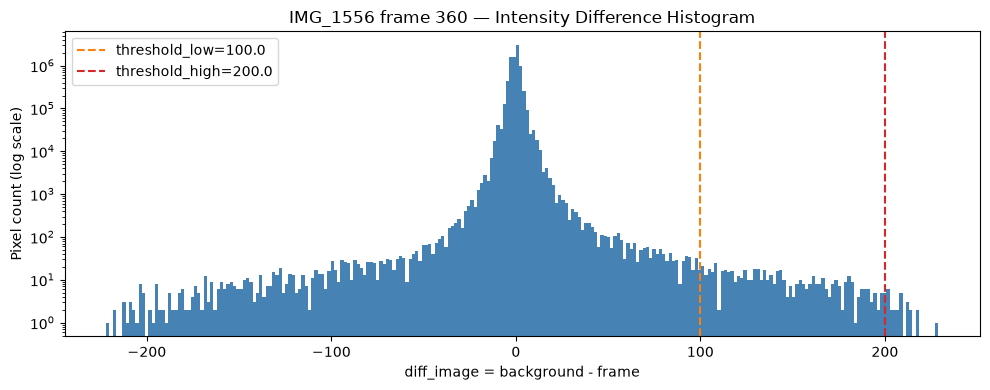

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(diff_image.ravel(), bins=256, color="steelblue")
ax.axvline(THRESHOLD_LOW, color="C1", linestyle="--", linewidth=1.5, label=f"threshold_low={THRESHOLD_LOW}")
ax.axvline(THRESHOLD_HIGH, color="C3", linestyle="--", linewidth=1.5, label=f"threshold_high={THRESHOLD_HIGH}")
ax.set_yscale("log")
ax.set_xlabel("diff_image = background - frame")
ax.set_ylabel("Pixel count (log scale)")
ax.set_title(f"{VIDEO_NAME} frame {FRAME_INDEX} — Intensity Difference Histogram")
ax.legend()
plt.tight_layout()
plt.show()


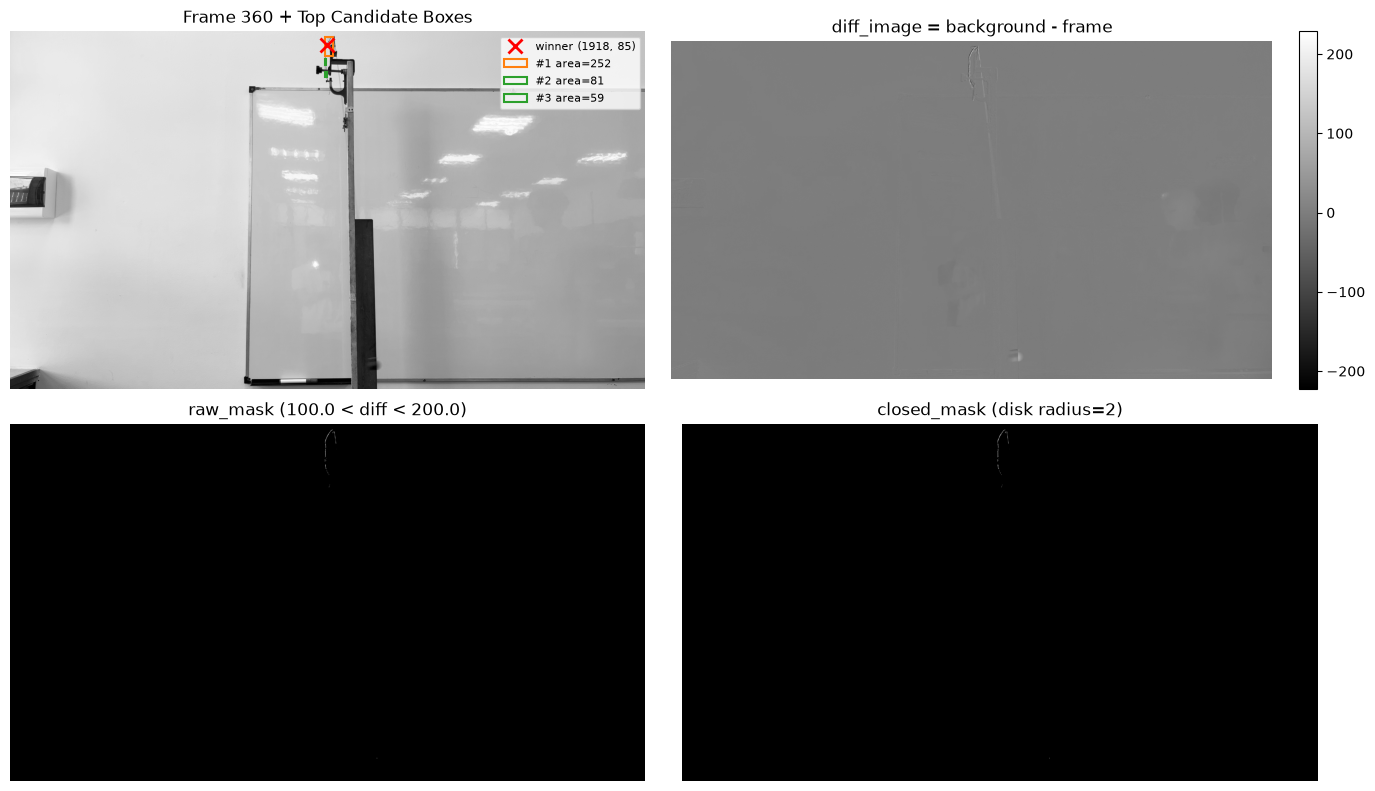

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
(ax_frame, ax_diff), (ax_raw, ax_closed) = axes

ax_frame.imshow(frame_gray, cmap="gray")
if not np.isnan(x_px) and not np.isnan(y_px):
    ax_frame.plot(x_px, y_px, "rx", markersize=10, markeredgewidth=2, label=f"winner ({x_px:.0f}, {y_px:.0f})")
for rank, reg in enumerate(regions[:3], start=1):
    min_r, min_c, max_r, max_c = reg.bbox
    rect = patches.Rectangle(
        (min_c, min_r),
        max_c - min_c,
        max_r - min_r,
        linewidth=1.5,
        edgecolor="C1" if rank == 1 else "C2",
        facecolor="none",
        label=f"#{rank} area={int(reg.area)}",
    )
    ax_frame.add_patch(rect)
ax_frame.set_title(f"Frame {FRAME_INDEX} + Top Candidate Boxes")
ax_frame.legend(loc="upper right", fontsize=8)
ax_frame.axis("off")

im_diff = ax_diff.imshow(diff_image, cmap="gray")
fig.colorbar(im_diff, ax=ax_diff, fraction=0.046, pad=0.04)
ax_diff.set_title("diff_image = background - frame")
ax_diff.axis("off")

ax_raw.imshow(raw_mask, cmap="gray")
ax_raw.set_title(f"raw_mask ({THRESHOLD_LOW} < diff < {THRESHOLD_HIGH})")
ax_raw.axis("off")

ax_closed.imshow(closed_mask, cmap="gray")
ax_closed.set_title(f"closed_mask (disk radius={MORPHOLOGY_DISK_RADIUS})")
ax_closed.axis("off")

plt.tight_layout()
plt.show()


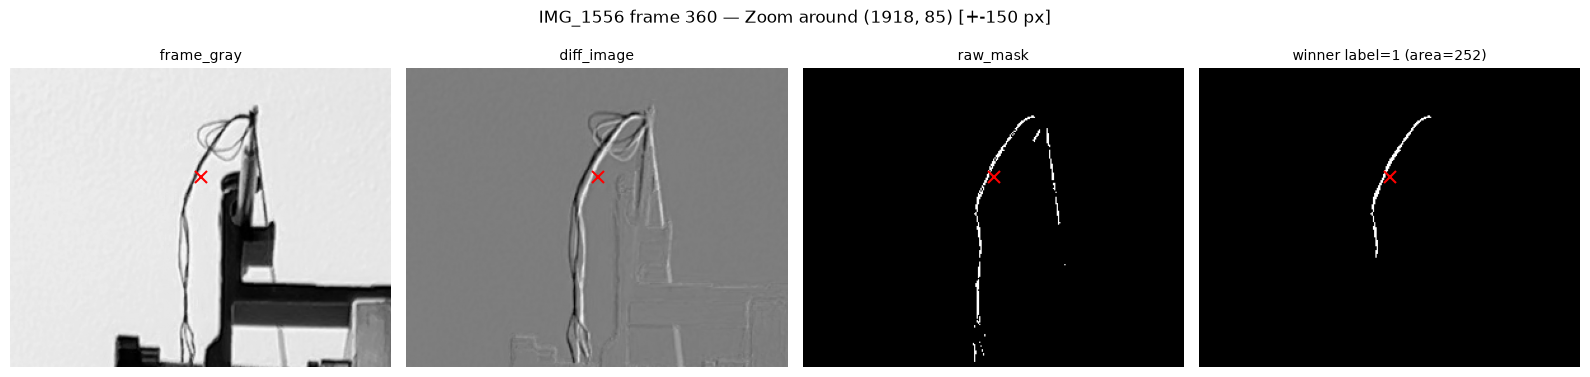

In [6]:
if regions:
    winning_reg = regions[0]
    cx: int = int(round(float(winning_reg.centroid[1])))
    cy: int = int(round(float(winning_reg.centroid[0])))
    half_crop: int = 150
    h_img, w_img = frame_gray.shape
    x0: int = max(0, cx - half_crop)
    x1: int = min(w_img, cx + half_crop)
    y0: int = max(0, cy - half_crop)
    y1: int = min(h_img, cy + half_crop)

    isolated_mask = labels[y0:y1, x0:x1] == winning_reg.label
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    panels = [
        (frame_gray[y0:y1, x0:x1], "frame_gray"),
        (diff_image[y0:y1, x0:x1], "diff_image"),
        (raw_mask[y0:y1, x0:x1], "raw_mask"),
        (isolated_mask, f"winner label={winning_reg.label} (area={int(winning_reg.area)})"),
    ]
    for ax, (patch_img, title) in zip(axes, panels, strict=True):
        ax.imshow(patch_img, cmap="gray")
        ax.plot(cx - x0, cy - y0, "rx", markersize=8, markeredgewidth=1.5)
        ax.set_title(title, fontsize=10)
        ax.axis("off")
    fig.suptitle(f"{VIDEO_NAME} frame {FRAME_INDEX} — Zoom around ({cx}, {cy}) [+-{half_crop} px]")
    plt.tight_layout()
    plt.show()
else:
    print("No connected components found for current thresholds.")
